Tugas Praktikum 2 - Citra siang/malam dengan fitur histogram + SVM RBF.

Beda dari praktikum 5 (fitur tunggal rata-rata kecerahan): di sini fitur berupa
histogram HSV 3 kanal (H=16, S=8, V=8 bin, ternormalisasi) => 32 dimensi.
Split 80:20, hyperparameter tuning C x gamma, dilaporkan akurasinya.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("citra_histogram.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js11-klasifikasi-2\tugas


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import cv2
import numpy as np
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

BASE = Path(__file__).resolve().parent.parent
DATA = BASE / "data" / "images"
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

[data] total=400 citra, dimensi fitur=32 (H16+S8+V8)
[data] distribusi kelas: night=200 day=200
[split 80:20] train=320 test=80

[grid] gamma x C (akurasi test, fitur histogram):
  gamma=0.01  C=1    acc_test=0.9750
  gamma=0.01  C=10   acc_test=0.9875
  gamma=0.01  C=100  acc_test=0.9875
  gamma=0.05  C=1    acc_test=1.0000
  gamma=0.05  C=10   acc_test=0.9875
  gamma=0.05  C=100  acc_test=0.9875
  gamma=0.1   C=1    acc_test=1.0000
  gamma=0.1   C=10   acc_test=0.9875
  gamma=0.1   C=100  acc_test=0.9875
  gamma=0.5   C=1    acc_test=0.9125
  gamma=0.5   C=10   acc_test=0.9125
  gamma=0.5   C=100  acc_test=0.9125
[terbaik] gamma=0.05, C=1, acc_test=1.0000
[model] akurasi train = 1.0000
[model] akurasi test  = 1.0000
[model] classification_report (test):
              precision    recall  f1-score   support

       night     1.0000    1.0000    1.0000        40
         day     1.0000    1.0000    1.0000        40

    accuracy                         1.0000        80
   macro avg    

[selesai] tugas 2


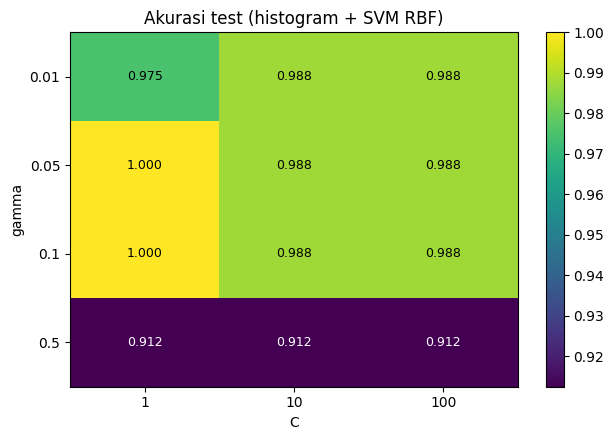

In [3]:
def load_features(root):
    """Histogram HSV tiap citra + label (day=1, night=0)."""
    feats, labels = [], []
    for f in sorted(Path(root).rglob("*.jpg")):
        lab = 1 if f.parent.name == "day" else 0
        img = cv2.imread(str(f))
        if img is None:
            continue
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        n = img[:, :, 0].size
        h = cv2.calcHist([hsv], [0], None, [16], [0, 180]).ravel() / n
        s = cv2.calcHist([hsv], [1], None, [8], [0, 256]).ravel() / n
        v = cv2.calcHist([hsv], [2], None, [8], [0, 256]).ravel() / n
        feats.append(np.concatenate([h, s, v]))
        labels.append(lab)
    return np.array(feats), np.array(labels)


X, y = load_features(DATA)
print(f"[data] total={len(X)} citra, dimensi fitur={X.shape[1]} (H16+S8+V8)")
print(f"[data] distribusi kelas: night={int((y == 0).sum())} day={int((y == 1).sum())}")

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=42,
                                      stratify=y)
print(f"[split 80:20] train={len(Xtr)} test={len(Xte)}")

rows = []
print("\n[grid] gamma x C (akurasi test, fitur histogram):")
for g in [0.01, 0.05, 0.1, 0.5]:
    for C in [1, 10, 100]:
        model = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma=g, C=C))
        model.fit(Xtr, ytr)
        acc = accuracy_score(yte, model.predict(Xte))
        rows.append((g, C, acc))
        print(f"  gamma={g:<5} C={C:<4} acc_test={acc:.4f}")

best = max(rows, key=lambda r: r[2])
print(f"[terbaik] gamma={best[0]}, C={best[1]}, acc_test={best[2]:.4f}")

model = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma=best[0], C=best[1]))
model.fit(Xtr, ytr)
ypred = model.predict(Xte)
print(f"[model] akurasi train = {accuracy_score(ytr, model.predict(Xtr)):.4f}")
print(f"[model] akurasi test  = {accuracy_score(yte, ypred):.4f}")
print("[model] classification_report (test):")
print(classification_report(yte, ypred, target_names=["night", "day"], digits=4))
print("[model] confusion matrix (test):\n", confusion_matrix(yte, ypred))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
gs = sorted({r[0] for r in rows})
cs = sorted({r[1] for r in rows})
grid = np.array([[next(r[2] for r in rows if r[0] == g and r[1] == C) for C in cs] for g in gs])
im = ax.imshow(grid, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(cs)), cs)
ax.set_yticks(range(len(gs)), gs)
ax.set(xlabel="C", ylabel="gamma", title="Akurasi test (histogram + SVM RBF)")
for i in range(len(gs)):
    for j in range(len(cs)):
        ax.text(j, i, f"{grid[i, j]:.3f}", ha="center", va="center",
                color="w" if grid[i, j] < 0.95 else "k", fontsize=9)
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUT / "01_grid_histogram.png", dpi=110)
print("[selesai] tugas 2")